In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import scipy

## schematic

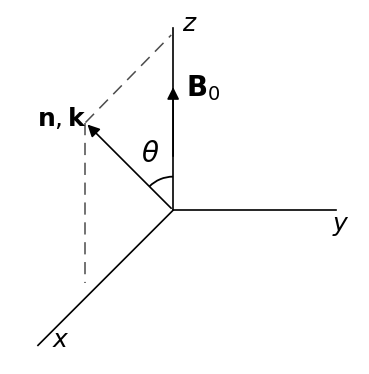

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.set_aspect("equal")
ax.axis("off")

O = np.array([0.0, 0.0])

# Axis endpoints
x_end = np.array([-1.45, -1.45])
y_end = np.array([ 1.75,  0.00])
z_end = np.array([ 0.00,  1.95])

# Coordinate axes
ax.plot([O[0], x_end[0]], [O[1], x_end[1]], color="black", lw=1.2)
ax.plot([O[0], y_end[0]], [O[1], y_end[1]], color="black", lw=1.2)
ax.plot([O[0], z_end[0]], [O[1], z_end[1]], color="black", lw=1.2)

# Axis labels
ax.text(x_end[0] + 0.15, x_end[1] - 0.02, r"$x$", fontsize=18)
ax.text(y_end[0] - 0.05, y_end[1] - 0.22, r"$y$", fontsize=18)
ax.text(z_end[0] + 0.09, z_end[1] - 0.02, r"$z$", fontsize=18)

# B0 arrow
ax.annotate(
    "",
    xy=(0, 1.35),
    xytext=(0, 0.55),
    arrowprops=dict(arrowstyle="-|>", lw=1.2, mutation_scale=18, color="black")
)
ax.text(0.14, 1.22, r"$\mathbf{B}_0$", fontsize=20)

# Vector n,k
theta = np.deg2rad(135)
r = 1.33
v = r * np.array([np.cos(theta), np.sin(theta)])

ax.annotate(
    "",
    xy=v,
    xytext=O,
    arrowprops=dict(arrowstyle="-|>", lw=1.2, mutation_scale=18, color="black")
)
ax.text(v[0] - 0.52, v[1] - 0.04, r"$\mathbf{n},\mathbf{k}$", fontsize=18)

# Dashed vertical projection line
proj = np.array([v[0], -0.78])
ax.plot(
    [v[0], v[0]],
    [v[1], proj[1]],
    ls=(0, (8, 5)),
    color="black",
    lw=1.1,
    alpha=0.7
)

# Dashed extension upward
ext2 = np.array([-0.02, 1.88])
ax.plot(
    [v[0], ext2[0]],
    [v[1], ext2[1]],
    ls=(0, (8, 5)),
    color="black",
    lw=1.1,
    alpha=0.7
)

# Theta angle shown as a plain arc, no arrowhead
theta_arc = Arc(
    O,
    width=0.72,
    height=0.72,
    angle=0,
    theta1=90,
    theta2=135,
    lw=1.3,
    color="black"
)
ax.add_patch(theta_arc)

ax.text(-0.34, 0.52, r"$\theta$", fontsize=20)

ax.set_xlim(-1.75, 2.0)
ax.set_ylim(-1.65, 2.15)

plt.show()

# hot

In [19]:
import sympy as sp

# ============================================================
# 1. Symbols
# ============================================================

I = sp.I

omega, k, theta = sp.symbols("omega k theta", real=True)
B0 = sp.symbols("B0", real=True)

mu0, eps0 = sp.symbols("mu0 eps0", positive=True)

# Species parameters
# alpha_s = q_s / m_s
alpha_e, alpha_p = sp.symbols("alpha_e alpha_p", real=True)

rho_e0, rho_p0 = sp.symbols("rho_e0 rho_p0", positive=True)
p_e0, p_p0 = sp.symbols("p_e0 p_p0", positive=True)

gamma_e, gamma_p = sp.symbols("gamma_e gamma_p", positive=True)

# ============================================================
# 2. Unknown perturbation variables
# ============================================================

rho_e1, p_e1 = sp.symbols("rho_e1 p_e1")
u_ex1, u_ey1, u_ez1 = sp.symbols("u_ex1 u_ey1 u_ez1")

rho_p1, p_p1 = sp.symbols("rho_p1 p_p1")
u_px1, u_py1, u_pz1 = sp.symbols("u_px1 u_py1 u_pz1")

E_x1, E_y1, E_z1 = sp.symbols("E_x1 E_y1 E_z1")
B_x1, B_y1, B_z1 = sp.symbols("B_x1 B_y1 B_z1")

u_e1 = sp.Matrix([u_ex1, u_ey1, u_ez1])
u_p1 = sp.Matrix([u_px1, u_py1, u_pz1])

E1 = sp.Matrix([E_x1, E_y1, E_z1])
B1 = sp.Matrix([B_x1, B_y1, B_z1])

# Unknown vector ordering
unknowns = [
    rho_e1, p_e1, u_ex1, u_ey1, u_ez1,
    rho_p1, p_p1, u_px1, u_py1, u_pz1,
    E_x1, E_y1, E_z1,
    B_x1, B_y1, B_z1
]

# ============================================================
# 3. Geometry
# ============================================================

# Background magnetic field: B0 along z
B0_vec = sp.Matrix([0, 0, B0])

# Wave vector k in the x-z plane.
# theta is the angle between k and B0, i.e. between k and z.
k_vec = sp.Matrix([
    k * sp.sin(theta),
    0,
    k * sp.cos(theta)
])

# ============================================================
# 4. Species-fluid equation builder
# ============================================================

def species_equations(
    name,
    rho1,
    p1,
    u1,
    rho0,
    p0,
    gamma,
    alpha
):
    """
    Build the 5 linearized fluid equations for one species.

    Unknowns for this species:
        rho1 : mass-density perturbation
        p1   : pressure perturbation
        u1   : velocity perturbation vector

    Linearized equations:

    1. Continuity:
        omega rho1 - rho0 k.u1 = 0

    2. Adiabatic pressure:
        omega p1 - gamma p0 k.u1 = 0

    3. Momentum:
        i omega rho0 u1
        - i k_vec p1
        - alpha rho0 E1
        - alpha rho0 u1 x B0_vec
        = 0
    """

    eqs = []

    # ----------------------------
    # Continuity equation
    # ----------------------------
    continuity = omega * rho1 - rho0 * k_vec.dot(u1)
    eqs.append((f"{name}: continuity", continuity))

    # ----------------------------
    # Adiabatic pressure equation
    # ----------------------------
    pressure = omega * p1 - gamma * p0 * k_vec.dot(u1)
    eqs.append((f"{name}: pressure closure", pressure))

    # ----------------------------
    # Momentum equation, vector form
    # ----------------------------
    momentum_vec = (
        I * omega * rho0 * u1
        - I * k_vec * p1
        - alpha * rho0 * E1
        - alpha * rho0 * u1.cross(B0_vec)
    )

    eqs.append((f"{name}: momentum x", momentum_vec[0]))
    eqs.append((f"{name}: momentum y", momentum_vec[1]))
    eqs.append((f"{name}: momentum z", momentum_vec[2]))

    return eqs

# ============================================================
# 5. Build all 16 equations
# ============================================================

eqs_labeled = []

# Electron equations: 5 scalar equations
eqs_labeled += species_equations(
    name="electron",
    rho1=rho_e1,
    p1=p_e1,
    u1=u_e1,
    rho0=rho_e0,
    p0=p_e0,
    gamma=gamma_e,
    alpha=alpha_e
)

# Proton equations: 5 scalar equations
eqs_labeled += species_equations(
    name="proton",
    rho1=rho_p1,
    p1=p_p1,
    u1=u_p1,
    rho0=rho_p0,
    p0=p_p0,
    gamma=gamma_p,
    alpha=alpha_p
)

# ----------------------------
# Faraday's law
#
# Starting equation:
#     curl E1 = - dB1/dt
#
# With convention exp[i(omega t - k.r)]:
#     nabla -> -i k
#     d/dt -> i omega
#
# Therefore:
#     k x E1 - omega B1 = 0
# ----------------------------

faraday_vec = k_vec.cross(E1) - omega * B1

eqs_labeled.append(("Faraday x", faraday_vec[0]))
eqs_labeled.append(("Faraday y", faraday_vec[1]))
eqs_labeled.append(("Faraday z", faraday_vec[2]))

# ----------------------------
# Ampere-Maxwell law
#
# Starting equation:
#     curl B1 = mu0 J1 + mu0 eps0 dE1/dt
#
# Linearized current:
#     J1 = alpha_e rho_e0 u_e1 + alpha_p rho_p0 u_p1
#
# With convention exp[i(omega t - k.r)]:
#     -i k x B1
#     - mu0 J1
#     - i omega mu0 eps0 E1 = 0
# ----------------------------

J1 = alpha_e * rho_e0 * u_e1 + alpha_p * rho_p0 * u_p1

ampere_vec = (
    -I * k_vec.cross(B1)
    - mu0 * J1
    - I * omega * mu0 * eps0 * E1
)

eqs_labeled.append(("Ampere x", ampere_vec[0]))
eqs_labeled.append(("Ampere y", ampere_vec[1]))
eqs_labeled.append(("Ampere z", ampere_vec[2]))

# Check equation count
print("Number of scalar equations:", len(eqs_labeled))
print("Number of unknowns:", len(unknowns))

# ============================================================
# 6. Convert equations to matrix form
# ============================================================

eqs = [expr for label, expr in eqs_labeled]

M_theta, b_theta = sp.linear_eq_to_matrix(eqs, unknowns)

print("M_theta shape:", M_theta.shape)
print("b_theta:")
sp.pprint(b_theta)

# This is the general oblique matrix with
# k = k(sin theta, 0, cos theta)
print("\nGeneral theta matrix M_theta:")
sp.pprint(M_theta)

# ============================================================
# 7. Plug in theta = 0: k parallel to B0
# ============================================================

M_parallel = sp.simplify(M_theta.subs(theta, 0))
b_parallel = sp.simplify(b_theta.subs(theta, 0))

print("\nParallel-propagation matrix M_parallel:")
sp.pprint(M_parallel)

print("\nb_parallel:")
sp.pprint(b_parallel)

# ============================================================
# 8. Optional: determinant
# ============================================================

# Warning:
# The full 16x16 determinant can be large.
# But for theta=0 it should factor into longitudinal and transverse pieces.

det_parallel = sp.factor(M_parallel.det())

print("\nFactored determinant for theta = 0:")
sp.pprint(det_parallel)


Number of scalar equations: 16
Number of unknowns: 16
M_theta shape: (16, 16)
b_theta:
⎡0⎤
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎢0⎥
⎢ ⎥
⎣0⎦

General theta matrix M_theta:
⎡ω       0        -k⋅ρₑ₀⋅sin(θ)        0        -k⋅ρₑ₀⋅cos(θ)    0       0     ↪
⎢                                                                              ↪
⎢0       ω       -γₑ⋅k⋅pₑ₀⋅sin(θ)      0       -γₑ⋅k⋅pₑ₀⋅cos(θ)  0       0     ↪
⎢                                                                              ↪
⎢0  -ⅈ⋅k⋅sin(θ)      ⅈ⋅ω⋅ρₑ₀       -B₀⋅αₑ⋅ρₑ₀         0          0       0     ↪
⎢                                                                              ↪
⎢0       0          B₀⋅αₑ⋅ρₑ₀       ⅈ⋅ω⋅ρₑ₀           0          0       0     ↪
⎢                                                                              ↪
⎢0  -ⅈ⋅k⋅cos(θ)         0              0           ⅈ⋅ω⋅ρₑ₀       0       0     ↪
⎢                            

In [20]:
M_theta

Matrix([
[omega,               0,       -k*rho_e0*sin(theta),                   0,       -k*rho_e0*cos(theta),     0,               0,                          0,                   0,                          0,                 0,                 0,                 0,               0,               0,              0],
[    0,           omega, -gamma_e*k*p_e0*sin(theta),                   0, -gamma_e*k*p_e0*cos(theta),     0,               0,                          0,                   0,                          0,                 0,                 0,                 0,               0,               0,              0],
[    0, -I*k*sin(theta),             I*omega*rho_e0,  -B0*alpha_e*rho_e0,                          0,     0,               0,                          0,                   0,                          0,   -alpha_e*rho_e0,                 0,                 0,               0,               0,              0],
[    0,               0,          B0*alpha_e*rho_e0,      

In [21]:
unknowns

[rho_e1,
 p_e1,
 u_ex1,
 u_ey1,
 u_ez1,
 rho_p1,
 p_p1,
 u_px1,
 u_py1,
 u_pz1,
 E_x1,
 E_y1,
 E_z1,
 B_x1,
 B_y1,
 B_z1]

In [22]:
M_parallel

Matrix([
[omega,     0,                   0,                   0,           -k*rho_e0,     0,     0,                   0,                   0,                   0,                 0,                 0,                 0,      0,      0,      0],
[    0, omega,                   0,                   0,     -gamma_e*k*p_e0,     0,     0,                   0,                   0,                   0,                 0,                 0,                 0,      0,      0,      0],
[    0,     0,      I*omega*rho_e0,  -B0*alpha_e*rho_e0,                   0,     0,     0,                   0,                   0,                   0,   -alpha_e*rho_e0,                 0,                 0,      0,      0,      0],
[    0,     0,   B0*alpha_e*rho_e0,      I*omega*rho_e0,                   0,     0,     0,                   0,                   0,                   0,                 0,   -alpha_e*rho_e0,                 0,      0,      0,      0],
[    0,  -I*k,                   0,        

In [23]:
M_parallel.det()

omega**2*(I*alpha_e**2*gamma_p*k**2*mu0*omega**2*p_p0*rho_e0**2 - I*alpha_e**2*mu0*omega**4*rho_e0**2*rho_p0 + I*alpha_p**2*gamma_e*k**2*mu0*omega**2*p_e0*rho_p0**2 - I*alpha_p**2*mu0*omega**4*rho_e0*rho_p0**2 + I*eps0*gamma_e*gamma_p*k**4*mu0*omega**2*p_e0*p_p0 - I*eps0*gamma_e*k**2*mu0*omega**4*p_e0*rho_p0 - I*eps0*gamma_p*k**2*mu0*omega**4*p_p0*rho_e0 + I*eps0*mu0*omega**6*rho_e0*rho_p0)*(-B0**4*alpha_e**2*alpha_p**2*eps0**2*mu0**2*omega**4*rho_e0**2*rho_p0**2 + 2*B0**4*alpha_e**2*alpha_p**2*eps0*k**2*mu0*omega**2*rho_e0**2*rho_p0**2 - B0**4*alpha_e**2*alpha_p**2*k**4*rho_e0**2*rho_p0**2 + B0**2*alpha_e**4*alpha_p**2*mu0**2*omega**2*rho_e0**4*rho_p0**2 + 2*B0**2*alpha_e**3*alpha_p**3*mu0**2*omega**2*rho_e0**3*rho_p0**3 + B0**2*alpha_e**2*alpha_p**4*mu0**2*omega**2*rho_e0**2*rho_p0**4 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**3*rho_p0**2 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**2*rho_p0**3 + 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0

# cold

In [39]:
import sympy as sp

# ============================================================
# 1. Symbols
# ============================================================

I = sp.I

omega, k, theta = sp.symbols("omega k theta", real=True)
B0 = sp.symbols("B0", real=True)

mu0, eps0 = sp.symbols("mu0 eps0", positive=True)

# alpha_s = q_s / m_s
# For electrons alpha_e < 0, for protons alpha_p > 0
alpha_e, alpha_p = sp.symbols("alpha_e alpha_p", real=True)

rho_e0, rho_p0 = sp.symbols("rho_e0 rho_p0", positive=True)

# ============================================================
# 2. Unknown perturbation variables
# ============================================================

rho_e1 = sp.symbols("rho_e1")
u_ex1, u_ey1, u_ez1 = sp.symbols("u_ex1 u_ey1 u_ez1")

rho_p1 = sp.symbols("rho_p1")
u_px1, u_py1, u_pz1 = sp.symbols("u_px1 u_py1 u_pz1")

E_x1, E_y1, E_z1 = sp.symbols("E_x1 E_y1 E_z1")
B_x1, B_y1, B_z1 = sp.symbols("B_x1 B_y1 B_z1")

u_e1 = sp.Matrix([u_ex1, u_ey1, u_ez1])
u_p1 = sp.Matrix([u_px1, u_py1, u_pz1])

E1 = sp.Matrix([E_x1, E_y1, E_z1])
B1 = sp.Matrix([B_x1, B_y1, B_z1])

# Unknown vector ordering for the cold-plasma system
unknowns = [
    rho_e1, u_ex1, u_ey1, u_ez1,
    rho_p1, u_px1, u_py1, u_pz1,
    E_x1, E_y1, E_z1,
    B_x1, B_y1, B_z1
]

# ============================================================
# 3. Geometry
# ============================================================

# Background magnetic field: B0 along z
B0_vec = sp.Matrix([0, 0, B0])

# Wave vector k in x-z plane.
# theta is the angle between k and B0.
k_vec = sp.Matrix([
    k * sp.sin(theta),
    0,
    k * sp.cos(theta)
])

# ============================================================
# 4. Cold species-fluid equation builder
# ============================================================

def cold_species_equations(
    name,
    rho1,
    u1,
    rho0,
    alpha
):
    """
    Build the 4 cold-fluid equations for one species.

    Unknowns for this species:
        rho1 : mass-density perturbation
        u1   : velocity perturbation vector

    Cold-fluid linearized equations:

    1. Continuity:
        omega rho1 - rho0 k.u1 = 0

    2. Momentum:
        i omega rho0 u1
        - alpha rho0 E1
        - alpha rho0 u1 x B0_vec
        = 0

    Pressure is ignored:
        p1 = 0
        grad p1 = 0
    """

    eqs = []

    # ----------------------------
    # Continuity equation
    # ----------------------------
    continuity = omega * rho1 - rho0 * k_vec.dot(u1)
    eqs.append((f"{name}: continuity", continuity))

    # ----------------------------
    # Cold momentum equation
    # ----------------------------
    momentum_vec = (
        I * omega * rho0 * u1
        - alpha * rho0 * E1
        - alpha * rho0 * u1.cross(B0_vec)
    )

    eqs.append((f"{name}: momentum x", momentum_vec[0]))
    eqs.append((f"{name}: momentum y", momentum_vec[1]))
    eqs.append((f"{name}: momentum z", momentum_vec[2]))

    return eqs

# ============================================================
# 5. Build all 14 cold-plasma equations
# ============================================================

eqs_labeled = []

# Electron cold-fluid equations: 4 scalar equations
eqs_labeled += cold_species_equations(
    name="electron",
    rho1=rho_e1,
    u1=u_e1,
    rho0=rho_e0,
    alpha=alpha_e
)

# Proton cold-fluid equations: 4 scalar equations
eqs_labeled += cold_species_equations(
    name="proton",
    rho1=rho_p1,
    u1=u_p1,
    rho0=rho_p0,
    alpha=alpha_p
)

# ----------------------------
# Faraday's law
#
# Starting equation:
#     curl E1 = - dB1/dt
#
# Convention:
#     exp[i(omega t - k.r)]
#     nabla -> -i k
#     d/dt -> i omega
#
# Therefore:
#     k x E1 - omega B1 = 0
# ----------------------------

faraday_vec = k_vec.cross(E1) - omega * B1

eqs_labeled.append(("Faraday x", faraday_vec[0]))
eqs_labeled.append(("Faraday y", faraday_vec[1]))
eqs_labeled.append(("Faraday z", faraday_vec[2]))

# ----------------------------
# Ampere-Maxwell law
#
# Starting equation:
#     curl B1 = mu0 J1 + mu0 eps0 dE1/dt
#
# Linearized current:
#     J1 = alpha_e rho_e0 u_e1 + alpha_p rho_p0 u_p1
#
# Fourier form:
#     -i k x B1
#     - mu0 J1
#     - i omega mu0 eps0 E1 = 0
# ----------------------------

J1 = alpha_e * rho_e0 * u_e1 + alpha_p * rho_p0 * u_p1

ampere_vec = (
    -I * k_vec.cross(B1)
    - mu0 * J1
    - I * omega * mu0 * eps0 * E1
)

eqs_labeled.append(("Ampere x", ampere_vec[0]))
eqs_labeled.append(("Ampere y", ampere_vec[1]))
eqs_labeled.append(("Ampere z", ampere_vec[2]))

# ============================================================
# 6. Print equations
# ============================================================

print("Number of scalar equations:", len(eqs_labeled))
print("Number of unknowns:", len(unknowns))

print("\nCold-fluid equations:")
for label, expr in eqs_labeled:
    print(f"\n{label}:")
    sp.pprint(expr)

# ============================================================
# 7. Convert equations to matrix form
# ============================================================

eqs = [expr for label, expr in eqs_labeled]

M_theta, b_theta = sp.linear_eq_to_matrix(eqs, unknowns)

print("\nM_theta shape:", M_theta.shape)

print("\nGeneral oblique cold-plasma matrix M_theta:")
sp.pprint(M_theta)

print("\nb_theta:")
sp.pprint(b_theta)

# ============================================================
# 8. Substitute theta = 0: k parallel to B0
# ============================================================

M_parallel = sp.simplify(M_theta.subs(theta, 0))
b_parallel = sp.simplify(b_theta.subs(theta, 0))

print("\nParallel cold-plasma matrix M_parallel:")
sp.pprint(M_parallel)

print("\nb_parallel:")
sp.pprint(b_parallel)

# ============================================================
# 9. Optional determinant of full 14x14 matrix
# ============================================================

det_parallel = sp.factor(M_parallel.det())

print("\nFactored determinant for theta = 0:")
sp.pprint(det_parallel)

Number of scalar equations: 14
Number of unknowns: 14

Cold-fluid equations:

electron: continuity:
ω⋅ρₑ₁ - ρₑ₀⋅(k⋅uₑₓ₁⋅sin(θ) + k⋅u_ez1⋅cos(θ))

electron: momentum x:
-B₀⋅αₑ⋅ρₑ₀⋅u_ey1 - Eₓ₁⋅αₑ⋅ρₑ₀ + ⅈ⋅ω⋅ρₑ₀⋅uₑₓ₁

electron: momentum y:
B₀⋅αₑ⋅ρₑ₀⋅uₑₓ₁ - E_y1⋅αₑ⋅ρₑ₀ + ⅈ⋅ω⋅ρₑ₀⋅u_ey1

electron: momentum z:
-E_z1⋅αₑ⋅ρₑ₀ + ⅈ⋅ω⋅ρₑ₀⋅u_ez1

proton: continuity:
ω⋅ρₚ₁ - ρₚ₀⋅(k⋅uₚₓ₁⋅sin(θ) + k⋅u_pz1⋅cos(θ))

proton: momentum x:
-B₀⋅αₚ⋅ρₚ₀⋅u_py1 - Eₓ₁⋅αₚ⋅ρₚ₀ + ⅈ⋅ω⋅ρₚ₀⋅uₚₓ₁

proton: momentum y:
B₀⋅αₚ⋅ρₚ₀⋅uₚₓ₁ - E_y1⋅αₚ⋅ρₚ₀ + ⅈ⋅ω⋅ρₚ₀⋅u_py1

proton: momentum z:
-E_z1⋅αₚ⋅ρₚ₀ + ⅈ⋅ω⋅ρₚ₀⋅u_pz1

Faraday x:
-Bₓ₁⋅ω - E_y1⋅k⋅cos(θ)

Faraday y:
-B_y1⋅ω + Eₓ₁⋅k⋅cos(θ) - E_z1⋅k⋅sin(θ)

Faraday z:
-B_z1⋅ω + E_y1⋅k⋅sin(θ)

Ampere x:
ⅈ⋅B_y1⋅k⋅cos(θ) - ⅈ⋅Eₓ₁⋅eps₀⋅μ₀⋅ω - μ₀⋅(αₑ⋅ρₑ₀⋅uₑₓ₁ + αₚ⋅ρₚ₀⋅uₚₓ₁)

Ampere y:
-ⅈ⋅E_y1⋅eps₀⋅μ₀⋅ω - μ₀⋅(αₑ⋅ρₑ₀⋅u_ey1 + αₚ⋅ρₚ₀⋅u_py1) - ⅈ⋅(Bₓ₁⋅k⋅cos(θ) - B_z1⋅ ↪

↪ k⋅sin(θ))

Ampere z:
-ⅈ⋅B_y1⋅k⋅sin(θ) - ⅈ⋅E_z1⋅eps₀⋅μ₀⋅ω - μ₀⋅(αₑ⋅ρₑ₀⋅u_ez1 + αₚ⋅ρₚ₀⋅u_pz1)

M_theta shape: (14, 14)

Genera

In [40]:
sp.Matrix(unknowns)

Matrix([
[rho_e1],
[ u_ex1],
[ u_ey1],
[ u_ez1],
[rho_p1],
[ u_px1],
[ u_py1],
[ u_pz1],
[  E_x1],
[  E_y1],
[  E_z1],
[  B_x1],
[  B_y1],
[  B_z1]])

In [41]:
M_parallel

Matrix([
[omega,                   0,                   0,           -k*rho_e0,     0,                   0,                   0,                   0,                 0,                 0,                 0,      0,      0,      0],
[    0,      I*omega*rho_e0,  -B0*alpha_e*rho_e0,                   0,     0,                   0,                   0,                   0,   -alpha_e*rho_e0,                 0,                 0,      0,      0,      0],
[    0,   B0*alpha_e*rho_e0,      I*omega*rho_e0,                   0,     0,                   0,                   0,                   0,                 0,   -alpha_e*rho_e0,                 0,      0,      0,      0],
[    0,                   0,                   0,      I*omega*rho_e0,     0,                   0,                   0,                   0,                 0,                 0,   -alpha_e*rho_e0,      0,      0,      0],
[    0,                   0,                   0,                   0, omega,                   0, 

In [42]:
sp.simplify(M_parallel.det())

I*mu0*omega**4*rho_e0**3*rho_p0**3*(alpha_e**2*rho_e0 + alpha_p**2*rho_p0 - eps0*omega**2)*(B0**4*alpha_e**2*alpha_p**2*eps0**2*mu0**2*omega**4 - 2*B0**4*alpha_e**2*alpha_p**2*eps0*k**2*mu0*omega**2 + B0**4*alpha_e**2*alpha_p**2*k**4 - B0**2*alpha_e**4*alpha_p**2*mu0**2*omega**2*rho_e0**2 - 2*B0**2*alpha_e**3*alpha_p**3*mu0**2*omega**2*rho_e0*rho_p0 - B0**2*alpha_e**2*alpha_p**4*mu0**2*omega**2*rho_p0**2 + 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0 + 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_p0 - 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0 - 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_p0 - B0**2*alpha_e**2*eps0**2*mu0**2*omega**6 + 2*B0**2*alpha_e**2*eps0*k**2*mu0*omega**4 - B0**2*alpha_e**2*k**4*omega**2 - B0**2*alpha_p**2*eps0**2*mu0**2*omega**6 + 2*B0**2*alpha_p**2*eps0*k**2*mu0*omega**4 - B0**2*alpha_p**2*k**4*omega**2 + alpha_e**4*mu0**2*omega**4*rho_e0**2 + 2*alpha_e**2*alpha_p**2*mu0**2*omega**4*rho_e0*rho_p0 - 2*alpha_e**2*eps0*mu0

In [28]:
M_parallel.det()

omega**2*(-I*alpha_e**2*mu0*omega**2*rho_e0**2*rho_p0 - I*alpha_p**2*mu0*omega**2*rho_e0*rho_p0**2 + I*eps0*mu0*omega**4*rho_e0*rho_p0)*(-B0**4*alpha_e**2*alpha_p**2*eps0**2*mu0**2*omega**4*rho_e0**2*rho_p0**2 + 2*B0**4*alpha_e**2*alpha_p**2*eps0*k**2*mu0*omega**2*rho_e0**2*rho_p0**2 - B0**4*alpha_e**2*alpha_p**2*k**4*rho_e0**2*rho_p0**2 + B0**2*alpha_e**4*alpha_p**2*mu0**2*omega**2*rho_e0**4*rho_p0**2 + 2*B0**2*alpha_e**3*alpha_p**3*mu0**2*omega**2*rho_e0**3*rho_p0**3 + B0**2*alpha_e**2*alpha_p**4*mu0**2*omega**2*rho_e0**2*rho_p0**4 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**3*rho_p0**2 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**2*rho_p0**3 + 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0**3*rho_p0**2 + 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0**2*rho_p0**3 + B0**2*alpha_e**2*eps0**2*mu0**2*omega**6*rho_e0**2*rho_p0**2 - 2*B0**2*alpha_e**2*eps0*k**2*mu0*omega**4*rho_e0**2*rho_p0**2 + B0**2*alpha_e**2*k**4*omega**2*rho_e0**2*rho_

In [29]:
print(M_parallel.det())

omega**2*(-I*alpha_e**2*mu0*omega**2*rho_e0**2*rho_p0 - I*alpha_p**2*mu0*omega**2*rho_e0*rho_p0**2 + I*eps0*mu0*omega**4*rho_e0*rho_p0)*(-B0**4*alpha_e**2*alpha_p**2*eps0**2*mu0**2*omega**4*rho_e0**2*rho_p0**2 + 2*B0**4*alpha_e**2*alpha_p**2*eps0*k**2*mu0*omega**2*rho_e0**2*rho_p0**2 - B0**4*alpha_e**2*alpha_p**2*k**4*rho_e0**2*rho_p0**2 + B0**2*alpha_e**4*alpha_p**2*mu0**2*omega**2*rho_e0**4*rho_p0**2 + 2*B0**2*alpha_e**3*alpha_p**3*mu0**2*omega**2*rho_e0**3*rho_p0**3 + B0**2*alpha_e**2*alpha_p**4*mu0**2*omega**2*rho_e0**2*rho_p0**4 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**3*rho_p0**2 - 2*B0**2*alpha_e**2*alpha_p**2*eps0*mu0**2*omega**4*rho_e0**2*rho_p0**3 + 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0**3*rho_p0**2 + 2*B0**2*alpha_e**2*alpha_p**2*k**2*mu0*omega**2*rho_e0**2*rho_p0**3 + B0**2*alpha_e**2*eps0**2*mu0**2*omega**6*rho_e0**2*rho_p0**2 - 2*B0**2*alpha_e**2*eps0*k**2*mu0*omega**4*rho_e0**2*rho_p0**2 + B0**2*alpha_e**2*k**4*omega**2*rho_e0**2*rho_

# dispersion plot

$$
n^2=L=1-\sum_s \frac{\omega_{\mathrm{p} s}^2}{\omega\left(\omega-\omega_{\mathrm{c} s}\right)}
$$

$$
L=1-\sum_s \frac{\omega_{p s}^2}{\Omega_s} \frac{1}{\omega-\Omega_s}
$$


at zero frequency, n^2 is 1

$$
\omega_{ps}^2/\Omega_{cs}=n_s q_s^2 / (\epsilon_0 m_s) / (q_s B_0 / m_s) = n_s q_s / (\epsilon_0 B_0)
$$
Due to charge neutrality, the sum of n_s q_s is zero, so
$$ \sum_s \omega_{ps}^2/\Omega_{cs}=0$$
$$ n^2(\omega=0)=1$$

In [2]:

def plasma_frequencies(number_density, charge, mass, epsilon0):
    """
    Calculate the plasma frequencies for each species.

    Parameters:
    - number_density: List of number densities for each species.
    - charge: List of charges for each species.
    - mass: List of masses for each species.
    - epsilon0: Permittivity of free space.

    Returns:
    - List of plasma frequencies for each species.
    """
    omega_ps = []
    for n, q, m in zip(number_density, charge, mass):
        omega_p = np.sqrt(n * q**2 / (m * epsilon0))
        omega_ps.append(omega_p)
    return omega_ps

def cyclotron_frequencies(charge, mass, B0):
    """
    Calculate the cyclotron frequencies for each species.

    Parameters:
    - charge: List of charges for each species.
    - mass: List of masses for each species.
    - B0: Background magnetic field strength.

    Returns:
    - List of cyclotron frequencies for each species.
    """
    Omega_s = []
    for q, m in zip(charge, mass):
        Omega = q * B0 / m
        Omega_s.append(Omega)
    return Omega_s




def L(omega, omega_ps,Omega_s):
    """
    Calculate the cold plasma dispersion relation L(omega).

    Parameters:
    - omega: Frequency variable.
    - omega_pe: Electron plasma frequency.
    - omega_pp: Proton plasma frequency.
    - Omega_e: Electron cyclotron frequency.
    - Omega_p: Proton cyclotron frequency.

    Returns:
    - Value of L(omega).
    """
    
    # The plasma contain multiple species, e.g., electrons and protons, and possibly others.
    # use this dispersion relation: L=1-\sum_s \frac{\omega_{p s}^2}{\Omega_s} \frac{1}{\omega-\Omega_s}
    
    L=1
    for i in range(len(charge)):
        L=L-omega_ps[i]**2/(Omega_s[i]*(omega-Omega_s[i]))
    return L

In [3]:
# specify the quantity of each species in the plasma, e.g., electron and proton
number_density=[2,1,1]
charge=[-1,1,1]
# Notice: charge neutrality
if sum([n*q for n,q in zip(number_density,charge)]) != 0:
    raise ValueError("Charge neutrality is violated!")
mass=[1./2,1,2]
names=["electron","proton","ion"]
epsilon0=1 #8.854187817e-12

omega_ps = plasma_frequencies(number_density, charge, mass, epsilon0)
Omega_s = cyclotron_frequencies(charge, mass, B0=1)

In [4]:
omega_ps

[np.float64(2.0), np.float64(1.0), np.float64(0.7071067811865476)]

In [5]:
Omega_s

[-2.0, 1.0, 0.5]

## n^2 plot

Text(0, 0.5, '$L(\\omega)=n^2$')

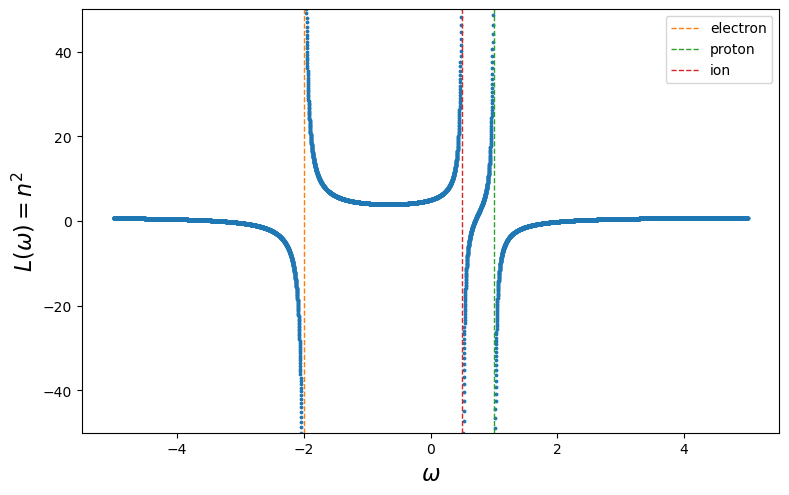

In [15]:
omega_min, omega_max = -5.0, 5.0
omega_values = np.linspace(omega_min, omega_max, 10000)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(omega_values, L(omega_values, omega_ps, Omega_s), s=3)
for i in range(len(charge)):
    ax.axvline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    
ax.legend()
ax.set_ylim(-50,50)
# ax.set_yscale("symlog",linthresh=1e-1)
# ax.set_xscale("symlog",linthresh=1e-1)
ax.set_xlabel(r"$\omega$", fontsize=16)
ax.set_ylabel(r"$L(\omega)=n^2$", fontsize=16)

## omega-k

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_58712/4126457384.py:7: RuntimeWarning: invalid value encountered in sqrt
  ax.scatter(omega_values, omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), label="Dispersion Relation",s=1)


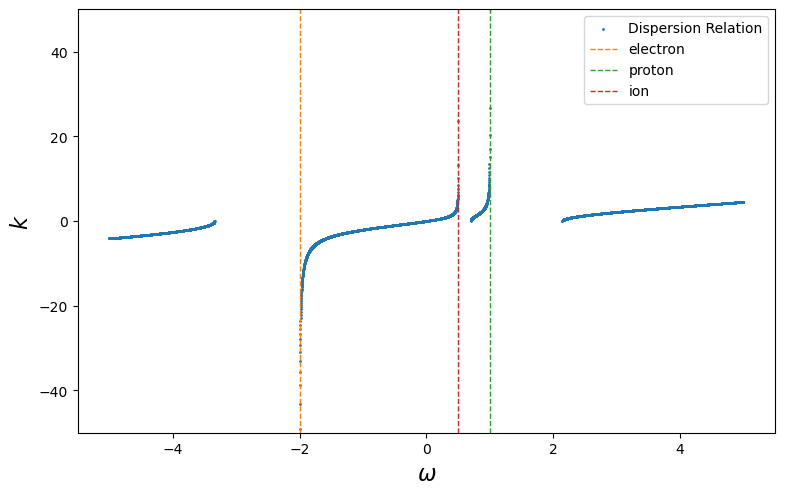

In [16]:
#omega-k plot
omega_min, omega_max = -5.0, 5.0
omega_values = np.linspace(omega_min, omega_max, 10000)


fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(omega_values, omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), label="Dispersion Relation",s=1)


for i in range(len(charge)):
    ax.axvline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    

ax.set_xlabel(r"$\omega$", fontsize=16)
ax.set_ylabel(r"$k$", fontsize=16)
# ax.set_yscale("symlog")
ax.set_ylim(-50,50)
ax.legend()

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_58712/1724116800.py:7: RuntimeWarning: invalid value encountered in sqrt
  ax.scatter(omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), omega_values, label="Dispersion Relation",s=1)


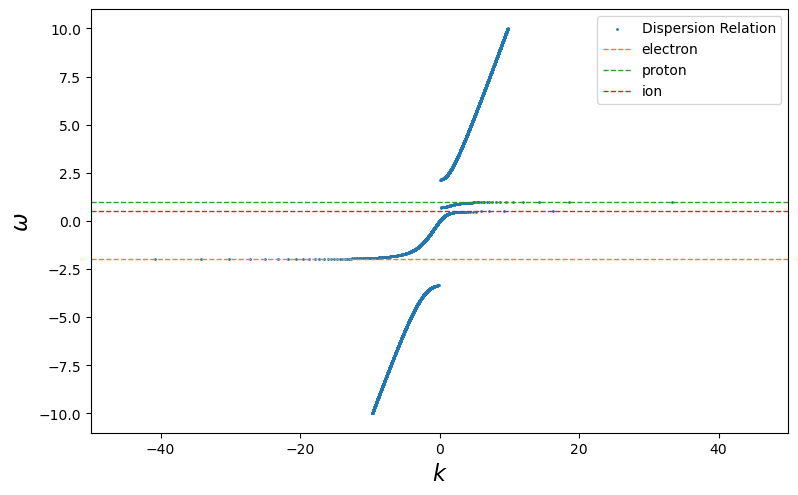

In [20]:
#omega-k plot
omega_min, omega_max = -10.0, 10.0
omega_values = np.linspace(omega_min, omega_max, 10000)


fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), omega_values, label="Dispersion Relation",s=1)


for i in range(len(charge)):
    ax.axhline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    

ax.set_ylabel(r"$\omega$", fontsize=16)
ax.set_xlabel(r"$k$", fontsize=16)
# ax.set_xscale("symlog")
ax.set_xlim(-50,50)
# ax.set_yscale("symlog")
ax.legend()

In [21]:
# same plot using plotly
#omega-k plot
omega_min, omega_max = -10.0, 10.0
omega_values = np.linspace(omega_min, omega_max, 10000)


fig=go.Figure()
fig.add_trace(go.Scatter(x=omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), y=omega_values, mode='markers', name='Dispersion Relation', marker=dict(size=2)))
for i in range(len(charge)):
    fig.add_trace(go.Scatter(x=[-50, 50], y=[Omega_s[i], Omega_s[i]], mode='lines', name=f"{names[i]}",
                                # line=dict(dash='dash', width=1.5, color=f"C{i+1}")
                                ))
    
fig.update_layout(
    title="Dispersion Relation",
    xaxis_title="k",
    yaxis_title="ω",
    legend_title="Species",
    font=dict(size=14),
    width=800,
    height=500
)
# add axes limits
fig.update_xaxes(range=[-10, 10], autorange=False)
fig.update_yaxes(range=[-10, 10], autorange=False)
fig.show()

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_58712/1744216251.py:8: RuntimeWarning:

invalid value encountered in sqrt



/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_58712/2130022579.py:21: RuntimeWarning:

invalid value encountered in sqrt

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_58712/2130022579.py:62: RuntimeWarning:

invalid value encountered in sqrt



Text(0.5, 1.0, 'Fewer protons, more ions')

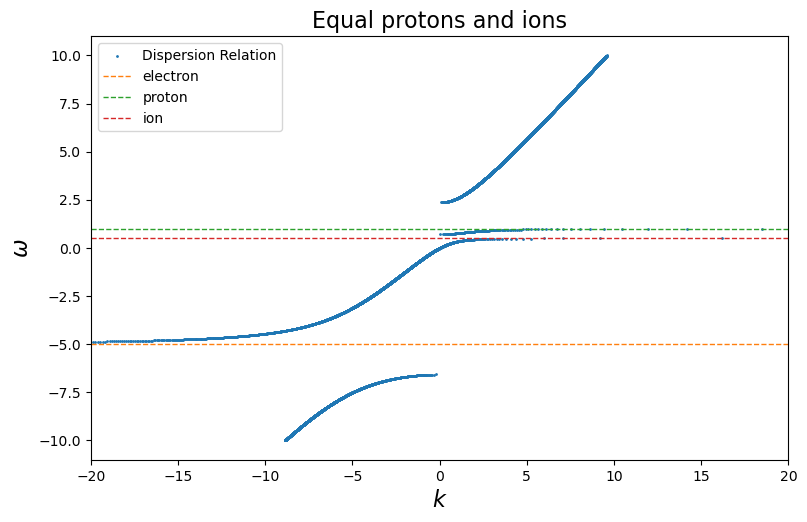

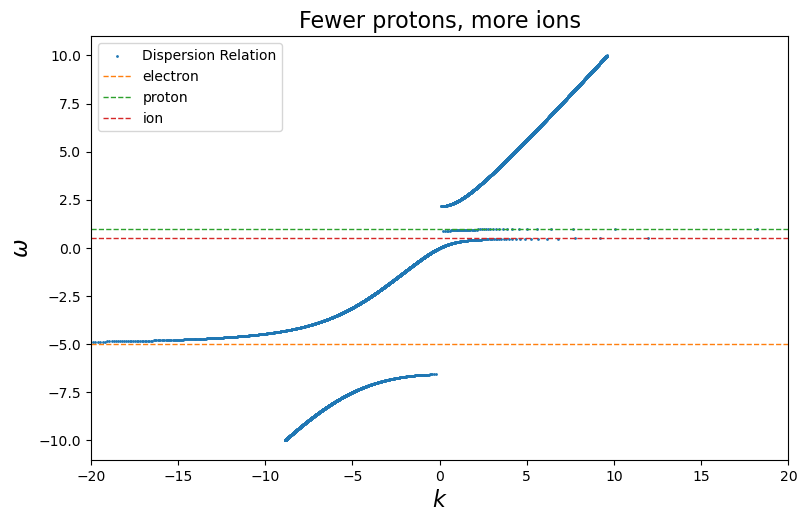

In [24]:
# specify the quantity of each species in the plasma, e.g., electron and proton
number_density=[2,1,1]
charge=[-1,1,1]
# Notice: charge neutrality
if sum([n*q for n,q in zip(number_density,charge)]) != 0:
    raise ValueError("Charge neutrality is violated!")
mass=[1./5,1,2]
names=["electron","proton","ion"]
epsilon0=1 #8.854187817e-12

omega_ps = plasma_frequencies(number_density, charge, mass, epsilon0)
Omega_s = cyclotron_frequencies(charge, mass, B0=1)


#omega-k plot
omega_min, omega_max = -10.0, 10.0
omega_values = np.linspace(omega_min, omega_max, 10000)


fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), omega_values, label="Dispersion Relation",s=1)


for i in range(len(charge)):
    ax.axhline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    

ax.set_ylabel(r"$\omega$", fontsize=16)
ax.set_xlabel(r"$k$", fontsize=16)
ax.legend()
ax.set_xlim(-20, 20)

ax.set_title("Equal protons and ions", fontsize=16)








# specify the quantity of each species in the plasma, e.g., electron and proton
number_density=[2,0.3,1.7]
charge=[-1,1,1]
# Notice: charge neutrality
if sum([n*q for n,q in zip(number_density,charge)]) != 0:
    raise ValueError("Charge neutrality is violated!")
mass=[1./5,1,2]
names=["electron","proton","ion"]
epsilon0=1 #8.854187817e-12

omega_ps = plasma_frequencies(number_density, charge, mass, epsilon0)
Omega_s = cyclotron_frequencies(charge, mass, B0=1)


#omega-k plot
omega_min, omega_max = -10.0, 10.0
omega_values = np.linspace(omega_min, omega_max, 10000)


fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), omega_values, label="Dispersion Relation",s=1)


for i in range(len(charge)):
    ax.axhline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    

ax.set_ylabel(r"$\omega$", fontsize=16)
ax.set_xlabel(r"$k$", fontsize=16)
ax.legend()
ax.set_xlim(-20, 20)
ax.set_title("Fewer protons, more ions", fontsize=16)







## Alfven to ICW

In [138]:
# specify the quantity of each species in the plasma, e.g., electron and proton
number_density=[2,1,1]
charge=[-1,1,1]
# Notice: charge neutrality
if sum([n*q for n,q in zip(number_density,charge)]) != 0:
    raise ValueError("Charge neutrality is violated!")
mass=[1./2,1,2]
names=["electron","proton","ion"]
epsilon0=1 #8.854187817e-12

omega_ps = plasma_frequencies(number_density, charge, mass, epsilon0)
Omega_s = cyclotron_frequencies(charge, mass, B0=1)

In [139]:
Omega_s

[-2.0, 1.0, 0.5]

In [146]:
# total density
rho=np.sum(np.array(number_density)*np.array(mass))

In [147]:
rho

np.float64(4.0)

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_25561/3235529087.py:61: RuntimeWarning:

divide by zero encountered in divide

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_25561/1949340063.py:7: RuntimeWarning:

invalid value encountered in sqrt



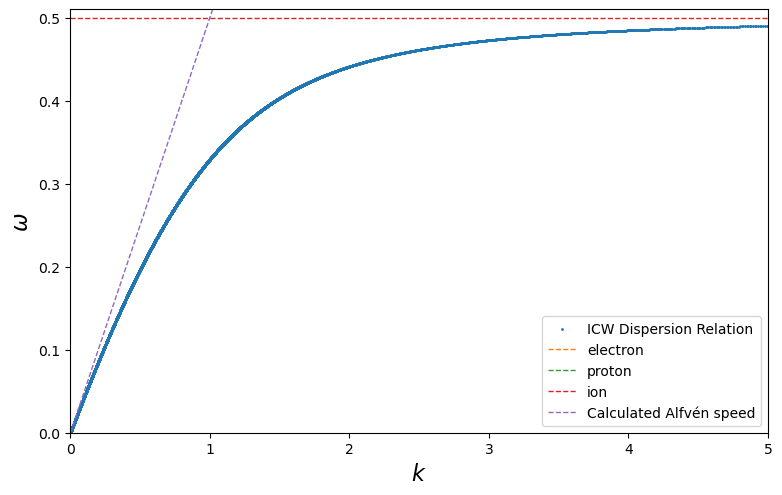

In [172]:
#omega-k plot
omega_min, omega_max = 0.0, 0.5
omega_values = np.linspace(omega_min, omega_max, 10000)


fig,ax=plt.subplots(figsize=(9,5.5))
ax.scatter(omega_values*np.sqrt(L(omega_values, omega_ps, Omega_s)), omega_values, label="ICW Dispersion Relation",s=1)


for i in range(len(charge)):
    ax.axhline(Omega_s[i], ls="--", lw=1.0, label=f"{names[i]}",c=f"C{i+1}")
    
# plot alfven speed. here we use mu_0=1, c=1,eps0=1, rho,B0=1, so v_A=B0/sqrt(mu0*rho)=1/sqrt(rho)
v_A=1/np.sqrt(rho)
ax.plot([0,5],[0,v_A*5],ls="--",lw=1.0,label="Calculated Alfvén speed",c="C4")

ax.set_ylabel(r"$\omega$", fontsize=16)
ax.set_xlabel(r"$k$", fontsize=16)
# ax.set_xscale("symlog")
# ax.set_yscale("symlog")

ax.set_ylim(0, 0.51)
ax.set_xlim(0, 5)
ax.legend()
# ax.set_aspect('equal')

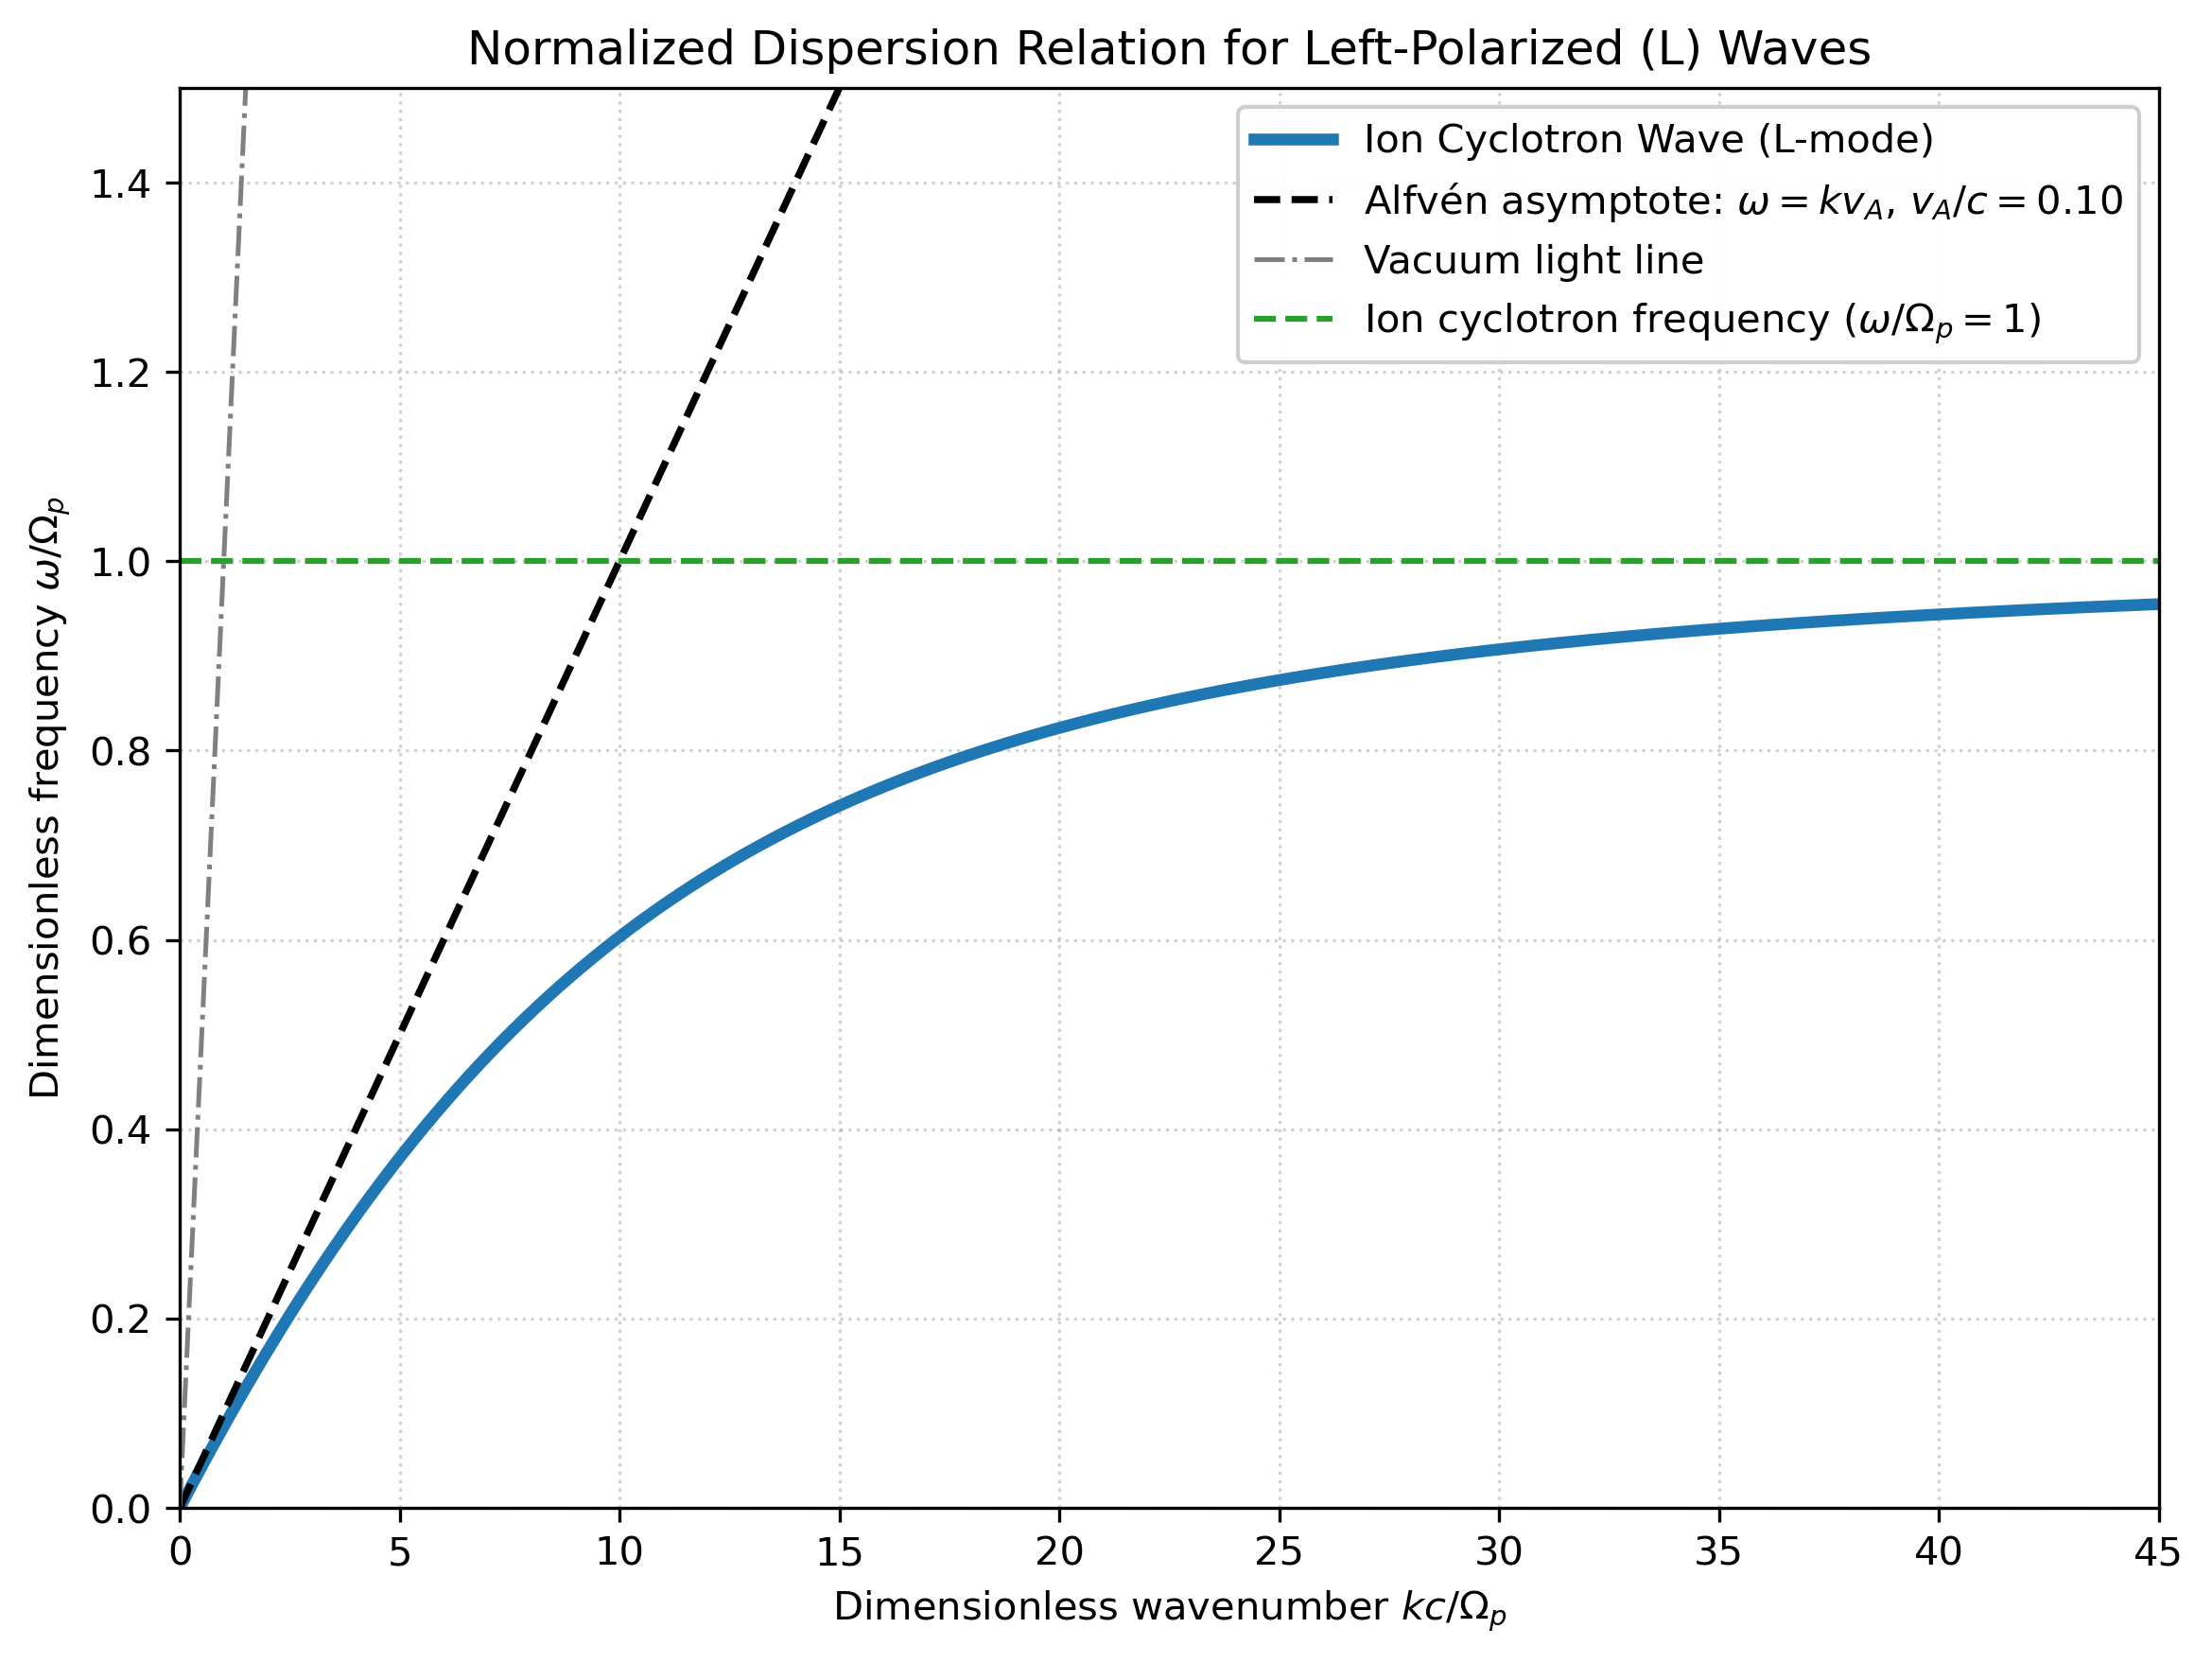

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# Plasma parameters
mi_me = 4.0
Omega_p, Omega_e = 1.0, -4.0
alpha = 10.0

omega_pp = alpha
omega_pe = np.sqrt(mi_me) * alpha

def n2_L(w):
    return (
        1
        - omega_pe**2 / (w * (w - Omega_e))
        - omega_pp**2 / (w * (w - Omega_p))
    )

# Ion-cyclotron branch
w = np.linspace(1e-3, Omega_p - 1e-3, 2000)
k = w * np.sqrt(n2_L(w))

# Dimensionless axes
w_norm = w / Omega_p
k_norm = k / Omega_p  # equivalent to k c / Omega_p if c = 1

# Alfvén asymptote: omega = k v_A
v_A = Omega_p / omega_pp
kA_norm = np.linspace(0, 45, 500)
wA_norm = v_A * kA_norm

# Vacuum light line: omega = ck
k_light_norm = np.linspace(0, 45, 500)
w_light_norm = k_light_norm

# Plot
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=300)

ax.plot(k_norm, w_norm, lw=3, label="Ion Cyclotron Wave (L-mode)")
ax.plot(kA_norm, wA_norm, "k--", lw=1.8,
        label=rf"Alfvén asymptote: $\omega = k v_A$, $v_A/c={v_A:.2f}$")
ax.plot(k_light_norm, w_light_norm, "-.", lw=1.2, color="gray",
        label=r"Vacuum light line")

ax.axhline(1, ls="--", lw=1.5, color="tab:green",
           label=r"Ion cyclotron frequency $(\omega/\Omega_p = 1)$")

ax.set(
    xlim=(0, 45),
    ylim=(0, 1.5),
    xlabel=r"Dimensionless wavenumber $kc/\Omega_p$",
    ylabel=r"Dimensionless frequency $\omega/\Omega_p$",
    title=r"Normalized Dispersion Relation for Left-Polarized (L) Waves"
)

ax.grid(True, ls=":", color="gray", alpha=0.35)
ax.legend(frameon=True, facecolor="white", framealpha=0.95, fontsize=10)

plt.show()

# Wave modes animation

## static

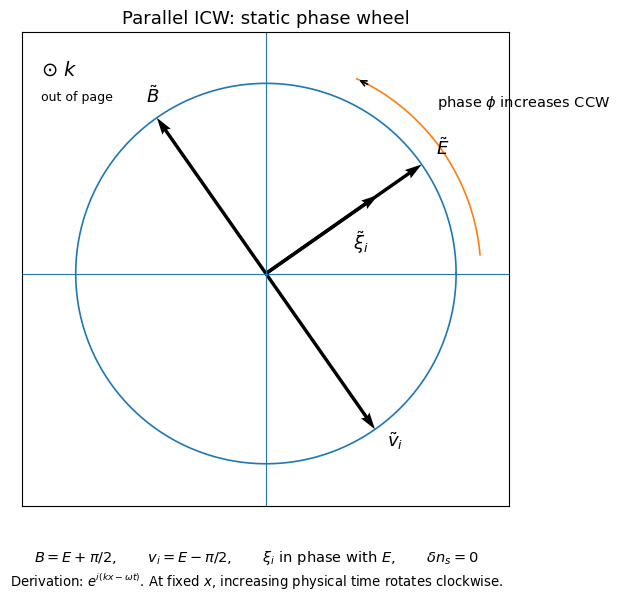

In [178]:
import numpy as np
import matplotlib.pyplot as plt

phi = np.deg2rad(35)

def vec(angle, r=1.0):
    return r * np.array([np.cos(angle), np.sin(angle)])

E  = vec(phi, 1.00)
B  = vec(phi + np.pi/2, 1.00)
vi = vec(phi - np.pi/2, 1.00)
xi = vec(phi, 0.72)

fig, ax = plt.subplots(figsize=(7.4, 6.4))

# Unit phase circle and axes
a = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(a), np.sin(a), linewidth=1.2)
ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

# Vectors
for v in (E, B, vi, xi):
    ax.quiver(0, 0, v[0], v[1],
              angles='xy', scale_units='xy', scale=1, width=0.007)

# Labels
ax.text(*(1.09*E),  r'$\tilde E$', fontsize=13)
ax.text(*(1.10*B),  r'$\tilde B$', fontsize=13)
ax.text(*(1.11*vi), r'$\tilde v_i$', fontsize=13)
ax.text(*(0.58*(xi+np.array([0.2,-0.2]))), r'$\tilde \xi_i$', fontsize=13)

# CCW phase arrow
arc = np.linspace(np.deg2rad(5), np.deg2rad(65), 80)
ax.plot(1.13*np.cos(arc), 1.13*np.sin(arc), linewidth=1.2)
p0 = vec(np.deg2rad(61), 1.13)
p1 = vec(np.deg2rad(65), 1.13)
ax.annotate("", xy=p1, xytext=p0,
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.text(0.90, 0.88, r'phase $\phi$ increases CCW', fontsize=10.5)

# k direction
ax.text(-1.18, 1.04, r'$\odot\ k$', fontsize=14)
ax.text(-1.18, 0.91, 'out of page', fontsize=9)

# Explanation
fig.text(
    0.5, 0.065,
    r'$B=E+\pi/2,\qquad v_i=E-\pi/2,\qquad \xi_i\ \mathrm{in\ phase\ with}\ E,\qquad \delta n_s=0$',
    ha='center', va='bottom', fontsize=10.5
)
fig.text(
    0.5, 0.025,
    r'Derivation: $e^{i(kx-\omega t)}$. At fixed $x$, increasing physical time rotates clockwise.',
    ha='center', va='bottom', fontsize=9.5
)

ax.set_title('Parallel ICW: static phase wheel', fontsize=13)
ax.set_aspect('equal')
ax.set_xlim(-1.28, 1.28)
ax.set_ylim(-1.22, 1.27)
ax.set_xticks([])
ax.set_yticks([])

fig.subplots_adjust(bottom=0.16, top=0.90)
plt.show()


## animation

In [ ]:
%%manim -qm -v WARNING ICWPhaseWheel
"""3Blue1Brown-style phase-wheel animation for a parallel ion-cyclotron wave.

Render with Manim Community Edition:
    manim -pqh icw_phase_wheel.py ICWPhaseWheel

The wheel deliberately animates the phasor phase phi counterclockwise.
For the Fourier convention exp[i(k z - omega t)], physical time evolution at
fixed z corresponds to decreasing phi, i.e. clockwise rotation.
"""

from manim import *
import numpy as np


class ICWPhaseWheel(Scene):
    def construct(self):
        self.camera.background_color = "#0B1020"

        # Palette inspired by Manim/3b1b defaults.
        E_COLOR = "#58C4DD"
        B_COLOR = "#FC6255"
        V_COLOR = "#83C167"
        XI_COLOR = "#FFFF00"
        GUIDE = "#75809A"

        center = LEFT * 2.7 + UP * 0.25
        radius = 2.25
        #initial E's phase angle
        phase = ValueTracker(np.deg2rad(35))

        title = Text("Parallel ICW — rotating phase wheel", font_size=38)
        title.to_edge(UP, buff=0.25)
        subtitle = MathTex(r"\phi\ \text{increases counterclockwise}", font_size=29)
        subtitle.next_to(title, DOWN, buff=0.12)

        circle = Circle(radius=radius, color=GUIDE, stroke_width=2.2).move_to(center)
        x_axis = Line(center + LEFT * 2.55, center + RIGHT * 2.55,
                      color=GUIDE, stroke_width=1.4).set_opacity(0.48)
        y_axis = Line(center + DOWN * 2.55, center + UP * 2.55,
                      color=GUIDE, stroke_width=1.4).set_opacity(0.48)
        origin = Dot(center, radius=0.045, color=WHITE)

        # angle offset, length, color, label, radial gap, tangential shift
        specs = [
            (0.0,     2.25, E_COLOR,  r"\widetilde{\mathbf E}",          0.30, -0.20),
            (PI / 2,  2.25, B_COLOR,  r"\widetilde{\mathbf B}",          0.30,  0.00),
            (-PI / 2, 2.25, V_COLOR,  r"\widetilde{\mathbf v}_i",        0.34,  0.00),
            (0.0,     1.43, XI_COLOR, r"\widetilde{\boldsymbol\xi}_i",  0.00,  0.30),
        ]

        def direction(offset):
            theta = phase.get_value() + offset
            return np.array([np.cos(theta), np.sin(theta), 0.0])

        def tangent(offset):
            d = direction(offset)
            return np.array([-d[1], d[0], 0.0])

        arrows = VGroup()
        labels = VGroup()
        for offset, length, color, label_tex, label_gap, tangent_shift in specs:
            arrow = always_redraw(
                lambda o=offset, ell=length, c=color: Arrow(
                    center,
                    center + ell * direction(o),
                    buff=0,
                    color=c,
                    stroke_width=7,
                    max_tip_length_to_length_ratio=0.13,
                )
            )
            label = always_redraw(
                lambda o=offset, ell=length, c=color, tex=label_tex,
                       g=label_gap, s=tangent_shift:
                MathTex(tex, color=c, font_size=31).move_to(
                    center + (ell + g) * direction(o) + s * tangent(o)
                )
            )
            arrows.add(arrow)
            labels.add(label)

        # Static curved arrow states the positive phase direction.
        phase_arc = Arc(
            radius=2.78,
            start_angle=np.deg2rad(8),
            angle=np.deg2rad(58),
            arc_center=center,
            color=E_COLOR,
            stroke_width=3,
        ).add_tip(tip_length=0.18, tip_width=0.14)
        phi_label = MathTex(r"+\phi", color=E_COLOR, font_size=28)
        phi_label.move_to(center + np.array([2.6, 2,1]))

        # Compact k-out-of-page marker.
        k_circle = Circle(radius=0.25, color=WHITE, stroke_width=2)
        k_dot = Dot(radius=0.07, color=WHITE)
        k_symbol = VGroup(k_circle, k_dot).move_to(RIGHT * 3.0 + UP * 1.55)
        k_label = MathTex(r"\mathbf k\ \text{out of page}", font_size=28)
        k_label.next_to(k_symbol, DOWN, buff=0.15)

        relation_1 = MathTex(
            r"\mathbf B=\mathbf E+\frac{\pi}{2}",
            r"\qquad",
            r"\mathbf v_i=\mathbf E-\frac{\pi}{2}",
            font_size=31,
        )
        relation_2 = MathTex(
            r"\boldsymbol\xi_i\parallel\mathbf E",
            r"\qquad",
            r"\delta n_s=0",
            font_size=31,
        )
        relations = VGroup(relation_1, relation_2).arrange(DOWN, buff=0.28)
        relations.move_to(RIGHT * 2.9 + DOWN * 0.1)

        convention = MathTex(
            r"e^{i(kz-\omega t)}:\ \text{at fixed }z,\ \text{physical time rotates clockwise}",
            font_size=25,
            color="#C7CAD1",
        )
        convention.to_edge(DOWN, buff=0.23)

        self.play(Write(title), FadeIn(subtitle, shift=UP * 0.1), run_time=1.2)
        self.play(
            Create(circle), Create(x_axis), Create(y_axis), FadeIn(origin),
            FadeIn(k_symbol), Write(k_label), run_time=1.2
        )
        self.play(
            LaggedStart(*[GrowArrow(a) for a in arrows], lag_ratio=0.12),
            FadeIn(labels), Create(phase_arc), FadeIn(phi_label),
            run_time=1.5,
        )
        self.play(Write(relations), FadeIn(convention), run_time=1.2)
        self.wait(0.5)

        # One full counterclockwise turn at constant angular speed.
        self.play(phase.animate.increment_value(TAU), run_time=8, rate_func=linear)
        self.wait(0.8)


Manim Community v0.20.1

In [14]:
center = LEFT * 2.7 + UP * 0.25
center

array([-2.7 ,  0.25,  0.  ])

In [4]:
config.media_embed = True

In [7]:
ICWPhaseWheel

__main__.ICWPhaseWheel

UsageError: %%manim is a cell magic, but the cell body is empty. Did you mean the line magic %manim (single %)?


In [27]:
%%manim -qm -v WARNING SquareDemo

class SquareDemo(Scene):
    def construct(self):
        square = Square(color=BLUE)     # 1. Create a blue square
        self.play(Create(square))       # 2. Show it (draws the square)
        self.play(Rotate(square, PI/4)) # 3. Rotate it 45 degrees (PI/4 radians)
        self.play(square.animate.shift(RIGHT * 3)) # 4. Move it 3 units right
        self.play(FadeOut(square))      # 5. Make it disappear

Manim Community v0.20.1